# Two-task resolved trajectory analysis

This notebook is organized into two independent analysis parts:

1. **Task 1 — `prove-plus-comm`** (easy)
2. **Task 2 — `protein-assembly`** (hard)

Each part contains its own resolved-run summary, harness/model breakdown, recorded tool analysis, representative selection, and four complete trajectories.

## Shared setup

The setup loads only the two selected Terminal-Bench 2.1 tasks. The analysis retains resolved real-model trajectories and excludes `<synthetic>` placeholders. The original data is not modified.

Following the study convention, models without a confirmed commercial classification are placed in the open-source/other model bucket. Commercial harnesses are Claude Code, Codex, Gemini CLI, and Cursor CLI.

In [28]:
from collections import Counter
from html import escape
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda value: f"{value:,.1f}")

In [29]:
# TASK_1 = "prove-plus-comm"
# TASK_2 = "protein-assembly"
# TASKS = [TASK_1, TASK_2]

# OPEN_MODEL_KEYWORDS = ("minimax", "glm", "llama", "mistral", "qwen", "deepseek", "gpt-oss")
# COMMERCIAL_MODEL_KEYWORDS = ("claude", "gpt", "gemini", "grok", "o1", "o3", "o4")
# COMMERCIAL_HARNESSES = {"cursor-cli", "claude-code", "codex", "gemini-cli"}

# def model_license(model):
#     value = (model or "").lower()
#     if any(keyword in value for keyword in OPEN_MODEL_KEYWORDS):
#         return "open-source"
#     if any(keyword in value for keyword in COMMERCIAL_MODEL_KEYWORDS):
#         return "commercial"
#     return "open-source"

# def harness_license(harness):
#     return "commercial" if harness in COMMERCIAL_HARNESSES else "open-source"

# def as_number(value):
#     try:
#         return float(value)
#     except (TypeError, ValueError):
#         return np.nan

# candidates = [
#     Path.cwd() / "data/curated/terminal_bench_2_1/trajectories.jsonl",
#     Path.cwd().parent / "data/curated/terminal_bench_2_1/trajectories.jsonl",
#     Path.cwd() / "design-decisions-by-LLMs/data/curated/terminal_bench_2_1/trajectories.jsonl",
# ]
# DATA_PATH = next((path.resolve() for path in candidates if path.exists()), None)
# if DATA_PATH is None:
#     raise FileNotFoundError("Could not find the curated Terminal-Bench 2.1 JSONL file.")

# records = []
# trajectory_by_id = {}
# with DATA_PATH.open(encoding="utf-8") as handle:
#     for line in handle:
#         trajectory = json.loads(line)
#         external = (trajectory.get("meta") or {}).get("downloaded_metadata") or {}
#         task = external.get("task_slug") or external.get("task_name")
#         if task not in TASKS:
#             continue
#         if trajectory.get("resolved") is not True or trajectory.get("model") == "<synthetic>":
#             continue

#         model_group = model_license(trajectory.get("model"))
#         harness_group = harness_license(trajectory.get("agent"))
#         trajectory_id = trajectory.get("id") or trajectory.get("trial_id")
#         trajectory_by_id[trajectory_id] = trajectory
#         records.append({
#             "task": task,
#             "model_license": model_group,
#             "harness_license": harness_group,
#             "combination": f"{model_group} model × {harness_group} harness",
#             "harness": trajectory.get("agent") or "unknown",
#             "model": trajectory.get("model") or "unknown",
#             "trajectory_id": trajectory_id,
#             "steps": len(trajectory.get("steps") or []),
#             "duration_min": as_number(external.get("duration_seconds")) / 60,
#             "prompt_tokens": as_number(external.get("prompt_tokens")),
#             "completion_tokens": as_number(external.get("completion_tokens")),
#             "total_tokens": as_number(external.get("total_tokens")),
#         })

# df = pd.DataFrame(records)
# task_1_df = df[df["task"] == TASK_1].copy()
# task_2_df = df[df["task"] == TASK_2].copy()

# print(f"Data: {DATA_PATH}")
# print(f"Task 1 resolved trajectories: {len(task_1_df):,}")
# print(f"Task 2 resolved trajectories: {len(task_2_df):,}")

In [30]:
TASK_1 = "cancel-async-tasks"
TASK_2 = "protein-assembly"
TASKS = [TASK_1, TASK_2]

OPEN_MODEL_KEYWORDS = ("minimax", "glm", "llama", "mistral", "qwen", "deepseek", "gpt-oss")
COMMERCIAL_MODEL_KEYWORDS = ("claude", "gpt", "gemini", "grok", "o1", "o3", "o4")
COMMERCIAL_HARNESSES = {"cursor-cli", "claude-code", "codex", "gemini-cli"}

def model_license(model):
    value = (model or "").lower()
    if any(keyword in value for keyword in OPEN_MODEL_KEYWORDS):
        return "open-source"
    if any(keyword in value for keyword in COMMERCIAL_MODEL_KEYWORDS):
        return "commercial"
    return "open-source"

def harness_license(harness):
    return "commercial" if harness in COMMERCIAL_HARNESSES else "open-source"

def as_number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return np.nan

candidates = [
    Path.cwd() / "data/curated/terminal_bench_2_1/trajectories.jsonl",
    Path.cwd().parent / "data/curated/terminal_bench_2_1/trajectories.jsonl",
    Path.cwd() / "design-decisions-by-LLMs/data/curated/terminal_bench_2_1/trajectories.jsonl",
]
DATA_PATH = next((path.resolve() for path in candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find the curated Terminal-Bench 2.1 JSONL file.")

records = []
trajectory_by_id = {}
with DATA_PATH.open(encoding="utf-8") as handle:
    for line in handle:
        trajectory = json.loads(line)
        external = (trajectory.get("meta") or {}).get("downloaded_metadata") or {}
        task = external.get("task_slug") or external.get("task_name")
        if task not in TASKS:
            continue
        if trajectory.get("resolved") is not True or trajectory.get("model") == "<synthetic>":
            continue

        model_group = model_license(trajectory.get("model"))
        harness_group = harness_license(trajectory.get("agent"))
        trajectory_id = trajectory.get("id") or trajectory.get("trial_id")
        trajectory_by_id[trajectory_id] = trajectory
        records.append({
            "task": task,
            "model_license": model_group,
            "harness_license": harness_group,
            "combination": f"{model_group} model × {harness_group} harness",
            "harness": trajectory.get("agent") or "unknown",
            "model": trajectory.get("model") or "unknown",
            "trajectory_id": trajectory_id,
            "steps": len(trajectory.get("steps") or []),
            "duration_min": as_number(external.get("duration_seconds")) / 60,
            "prompt_tokens": as_number(external.get("prompt_tokens")),
            "completion_tokens": as_number(external.get("completion_tokens")),
            "total_tokens": as_number(external.get("total_tokens")),
        })

df = pd.DataFrame(records)
task_1_df = df[df["task"] == TASK_1].copy()
task_2_df = df[df["task"] == TASK_2].copy()

print(f"Data: {DATA_PATH}")
print(f"Task 1 resolved trajectories: {len(task_1_df):,}")
print(f"Task 2 resolved trajectories: {len(task_2_df):,}")

Data: D:\Studies\UZH-M.Sc\THESIS\design-decisions-by-LLMs\data\curated\terminal_bench_2_1\trajectories.jsonl
Task 1 resolved trajectories: 50
Task 2 resolved trajectories: 24


In [31]:
def resolved_summary(task_df):
    return (
        task_df.groupby(["model_license", "harness_license"], sort=False)
        .agg(
            resolved_runs=("trajectory_id", "size"),
            median_steps=("steps", "median"),
            median_duration_min=("duration_min", "median"),
            median_prompt_tokens=("prompt_tokens", "median"),
            median_completion_tokens=("completion_tokens", "median"),
            median_total_tokens=("total_tokens", "median"),
        )
        .reset_index()
    )


TOKEN_COMBINATIONS = [
    ("commercial", "commercial"),
    ("commercial", "open-source"),
    ("open-source", "commercial"),
    ("open-source", "open-source"),
]
TOKEN_LABELS = [
    "Commercial model\nCommercial harness",
    "Commercial model\nOpen-source harness",
    "Open-source model\nCommercial harness",
    "Open-source model\nOpen-source harness",
]


def format_tokens(value):
    if pd.isna(value):
        return "N/A"
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    if value >= 1_000:
        return f"{value / 1_000:.1f}k"
    return f"{value:.0f}"


def plot_task_token_usage(task_df, title):
    """Plot mean prompt + completion tokens for resolved trajectories."""
    reported = task_df.dropna(subset=["prompt_tokens", "completion_tokens"]).copy()
    reported["reported_total_tokens"] = (
        reported["prompt_tokens"] + reported["completion_tokens"]
    )
    summary = (
        reported.groupby(["model_license", "harness_license"])
        .agg(
            n_token_runs=("trajectory_id", "size"),
            mean_prompt_tokens=("prompt_tokens", "mean"),
            mean_completion_tokens=("completion_tokens", "mean"),
            mean_total_tokens=("reported_total_tokens", "mean"),
        )
        .reindex(pd.MultiIndex.from_tuples(
            TOKEN_COMBINATIONS, names=["model_license", "harness_license"]
        ))
    )

    x = np.arange(len(TOKEN_COMBINATIONS))
    prompt = summary["mean_prompt_tokens"].to_numpy()
    completion = summary["mean_completion_tokens"].to_numpy()
    total = summary["mean_total_tokens"].to_numpy()
    maximum = float(np.nanmax(total))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.bar(x, prompt, color="#4C78A8", label="Prompt tokens")
    ax.bar(x, completion, bottom=prompt, color="#F28E2B", label="Completion tokens")
    for position, total_value, prompt_value, completion_value, n_runs in zip(
        x, total, prompt, completion, summary["n_token_runs"]
    ):
        if pd.isna(total_value):
            ax.text(position, maximum * 0.03, "N/A", ha="center", va="bottom")
            continue
        ax.text(
            position, total_value + maximum * 0.025,
            f"{format_tokens(total_value)}\n"
            f"(P {format_tokens(prompt_value)} + C {format_tokens(completion_value)}; n={int(n_runs)})",
            ha="center", va="bottom", fontsize=9,
        )

    ax.set_xticks(x, TOKEN_LABELS)
    ax.set_ylabel("Mean tokens per resolved trajectory")
    ax.yaxis.set_major_formatter(lambda value, _: format_tokens(value))
    ax.set_ylim(0, maximum * 1.22)
    ax.set_title(title, loc="left")
    ax.legend(frameon=False, ncols=2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.2)
    fig.tight_layout()
    plt.show()


def pair_summary(task_df):
    return (
        task_df.groupby(
            ["model_license", "harness_license", "harness", "model"],
            sort=False,
        )
        .agg(
            resolved_runs=("trajectory_id", "size"),
            median_steps=("steps", "median"),
            median_duration_min=("duration_min", "median"),
            median_total_tokens=("total_tokens", "median"),
        )
        .reset_index()
        .sort_values(
            ["model_license", "harness_license", "resolved_runs"],
            ascending=[True, True, False],
        )
    )

def recorded_action_label(action):
    if not action:
        return "no recorded action"
    return action.split(None, 1)[0]

def recorded_tool_summary(task_df):
    rows = []
    for record in task_df.itertuples(index=False):
        trajectory = trajectory_by_id[record.trajectory_id]
        labels = Counter(
            recorded_action_label(step.get("action"))
            for step in trajectory.get("steps") or []
        )
        for label, count in labels.items():
            rows.append({
                "model_license": record.model_license,
                "harness_license": record.harness_license,
                "recorded_action": label,
                "count": count,
            })
    tool_df = pd.DataFrame(rows)
    return (
        tool_df.groupby(
            ["model_license", "harness_license", "recorded_action"],
            sort=False,
        )["count"]
        .sum()
        .reset_index()
        .sort_values(
            ["model_license", "harness_license", "count"],
            ascending=[True, True, False],
        )
    )

def select_representatives(task_df):
    selected = []
    for _, group in task_df.groupby(["model_license", "harness_license"], sort=False):
        median_steps = group["steps"].median()
        ranked = group.assign(
            distance_from_median=(group["steps"] - median_steps).abs(),
            token_tiebreak=group["total_tokens"].fillna(np.inf),
        ).sort_values(["distance_from_median", "token_tiebreak", "trajectory_id"])
        selected.append(ranked.iloc[0])
    return pd.DataFrame(selected).reset_index(drop=True)

def json_html(value):
    return escape(json.dumps(value, indent=2, ensure_ascii=False, default=str))

def display_complete_trajectory(trajectory):
    external = (trajectory.get("meta") or {}).get("downloaded_metadata") or {}
    task = external.get("task_slug") or external.get("task_name") or trajectory.get("task_id")
    model_group = model_license(trajectory.get("model"))
    harness_group = harness_license(trajectory.get("agent"))
    title = (
        f"{task} | {model_group} model × {harness_group} harness | "
        f"{trajectory.get('agent')} + {trajectory.get('model')} | {trajectory.get('id')}"
    )
    top_level = {key: value for key, value in trajectory.items() if key not in {"meta", "steps"}}
    sections = [
        "<h4>Top-level fields</h4><pre>" + json_html(top_level) + "</pre>",
        "<h4>Complete meta field</h4><pre>" + json_html(trajectory.get("meta") or {}) + "</pre>",
    ]
    for position, step in enumerate(trajectory.get("steps") or []):
        sections.append(f"<h4>Step {position}</h4><pre>{json_html(step)}</pre>")
    display(HTML(
        f"<details style='margin:0.8em 0'>"
        f"<summary style='font-weight:600; cursor:pointer'>{escape(title)}</summary>"
        + "".join(sections)
        + "</details>"
    ))

# Part 1 — Task 1: `prove-plus-comm`

**Difficulty:** easy

The task is to complete a Coq induction proof of `forall n m : nat, n + m = m + n`, compile it with `coqc`, and produce `plus_comm.vo`. The usual strategy is induction on `n`, using the right-zero property in the base case and the induction hypothesis plus the successor property of addition in the inductive case.

## Task 1 resolved-run summary

Medians are used because token and duration distributions are right-skewed.

,model_license,harness_license,resolved_runs,median_steps,median_duration_min,median_prompt_tokens,median_completion_tokens,median_total_tokens
0,commercial,commercial,34,9.0,2.2,"94,817.0","6,870.0","101,977.0"
1,open-source,commercial,1,8.0,3.5,"166,586.0","6,658.0","173,244.0"
2,open-source,open-source,5,26.0,9.3,"616,698.0","34,787.0","651,485.0"
3,commercial,open-source,10,8.5,4.6,"15,687.0","13,736.0","30,778.0"


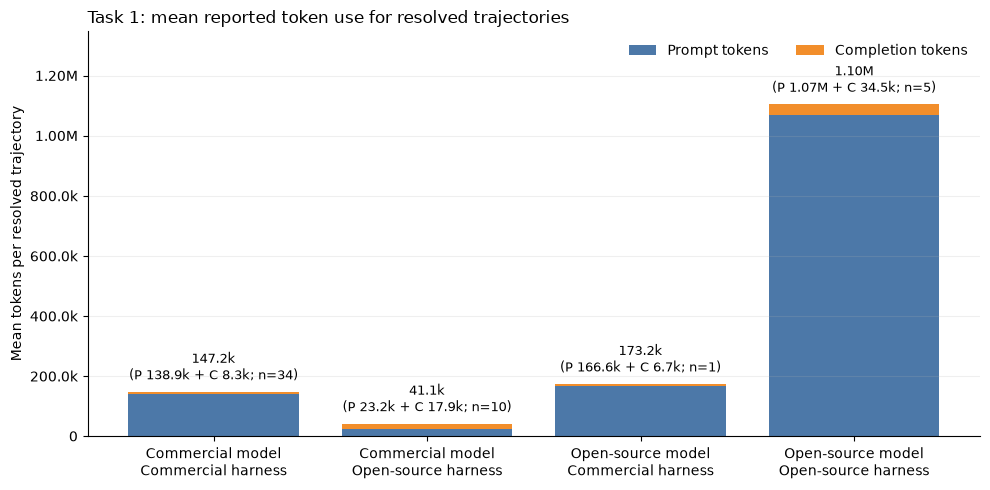

In [32]:
task_1_summary = resolved_summary(task_1_df)
display(task_1_summary)
plot_task_token_usage(
    task_1_df,
    "Task 1: mean reported token use for resolved trajectories",
)

## Task 1 resolved harness/model pairs

This shows the individual pairs contained within each of the four combinations.

In [33]:
task_1_pairs = pair_summary(task_1_df)
display(task_1_pairs)

,model_license,harness_license,harness,model,resolved_runs,median_steps,median_duration_min,median_total_tokens
0,commercial,commercial,claude-code,claude-fable-5,5,9.0,2.3,"46,103.0"
4,commercial,commercial,codex,gpt-5.5,5,11.0,2.1,"114,896.0"
6,commercial,commercial,codex,gpt-5.6-terra,5,7.0,1.6,"97,500.0"
8,commercial,commercial,gemini-cli,gemini-3.1-pro-preview-customtools,5,10.0,2.7,"165,788.0"
3,commercial,commercial,claude-code,claude-sonnet-5,4,11.0,2.6,"100,033.0"
2,commercial,commercial,claude-code,claude-opus-4-8,3,17.0,4.5,"185,987.0"
5,commercial,commercial,codex,gpt-5.6-luna,3,8.0,1.9,"117,659.0"
9,commercial,commercial,gemini-cli,gemini-3.1-pro-preview,3,5.0,1.8,"70,771.0"
7,commercial,commercial,cursor-cli,cursor/grok-4.5,1,20.0,6.3,"376,912.0"
14,commercial,open-source,terminus-2,openai/gpt-5.5,5,3.0,4.7,"27,274.0"


## Task 1 recorded tools

These are normalized action labels, not perfectly equivalent tool-call counts. Some harnesses store command details inside observations or collapse delegated work into one action.

In [34]:
task_1_tools = recorded_tool_summary(task_1_df)
display(task_1_tools)

,model_license,harness_license,recorded_action,count
0,commercial,commercial,Bash,123
2,commercial,commercial,no recorded action,54
9,commercial,commercial,exec,51
14,commercial,commercial,run_shell_command,37
7,commercial,commercial,exec_command,28
15,commercial,commercial,write_file,19
11,commercial,commercial,shellToolCall,14
13,commercial,commercial,update_topic,13
1,commercial,commercial,Read,11
6,commercial,commercial,Edit,11


## Task 1 representative resolved runs

One run is selected per combination. Its step count is closest to that combination's median resolved step count.

In [35]:
task_1_representatives = select_representatives(task_1_df)
display(task_1_representatives[[
    "model_license", "harness_license", "harness", "model",
    "trajectory_id", "steps", "duration_min", "prompt_tokens",
    "completion_tokens", "total_tokens",
]])

,model_license,harness_license,harness,model,trajectory_id,steps,duration_min,prompt_tokens,completion_tokens,total_tokens
0,commercial,commercial,claude-code,claude-opus-4-8,tbench21:b990e720-d502-5dd5-ad5b-984382f77124,9,1.8,"37,821.0","4,517.0","42,338.0"
1,open-source,commercial,claude-code,glm-5.1,tbench21:25c07789-084b-5a1e-901f-d10c4761f514,8,3.5,"166,586.0","6,658.0","173,244.0"
2,open-source,open-source,mini-swe-agent,openai/muse-spark-1.1,tbench21:1f42f951-40e6-5b08-aded-3ac887545534,26,9.3,"616,698.0","34,787.0","651,485.0"
3,commercial,open-source,terminus-2,gemini/gemini-3-pro-preview,tbench21:9ff67b3d-8c50-57a3-b323-8a70265380f0,9,3.0,"13,701.0","11,451.0","25,152.0"


## Task 1 complete trajectories

Expand each row to see the complete metadata and every recorded thought, action, observation, and timestamp. Nothing is truncated. Set `SHOW_ALL_TASK_1_RESOLVED = True` to display every resolved Task 1 run.

In [36]:
SHOW_ALL_TASK_1_RESOLVED = False

task_1_ids = (
    task_1_df["trajectory_id"].tolist()
    if SHOW_ALL_TASK_1_RESOLVED
    else task_1_representatives["trajectory_id"].tolist()
)
print(f"Displaying {len(task_1_ids)} complete Task 1 trajectories.")
for trajectory_id in task_1_ids:
    display_complete_trajectory(trajectory_by_id[trajectory_id])

Displaying 4 complete Task 1 trajectories.


In [ ]:
SHOW_ALL_TASK_1_RESOLVED = False

task_1_ids = (
    task_1_df["trajectory_id"].tolist()
    if SHOW_ALL_TASK_1_RESOLVED
    else task_1_representatives["trajectory_id"].tolist()
)
print(f"Displaying {len(task_1_ids)} complete Task 1 trajectories.")
for trajectory_id in task_1_ids:
    display_complete_trajectory(trajectory_by_id[trajectory_id])

# Part 2 — Task 2: `protein-assembly`

**Difficulty:** hard

The task is to research and assemble a gBlock in the order FLAG binder – Clover – DHFR – mCherry – SNAP-tag, separated by GS linkers. The agent must obtain the required source sequences, remove N-terminal methionines, reverse-translate the fusion protein, keep the DNA under 3000 nt, and maintain 30–70% GC in every sliding 50-nt window.

## Task 2 resolved-run summary

Medians are calculated only from resolved real-model trajectories.

,model_license,harness_license,resolved_runs,median_steps,median_duration_min,median_prompt_tokens,median_completion_tokens,median_total_tokens
0,open-source,commercial,2,49.0,29.9,"1,202,245.0","53,930.0","1,256,175.0"
1,commercial,commercial,14,38.0,6.8,"1,073,515.0","29,456.0","1,104,665.5"
2,open-source,open-source,2,54.5,11.7,"4,108,122.0","47,543.0","4,155,665.0"
3,commercial,open-source,6,30.0,20.5,"582,336.5","67,388.0","656,410.5"


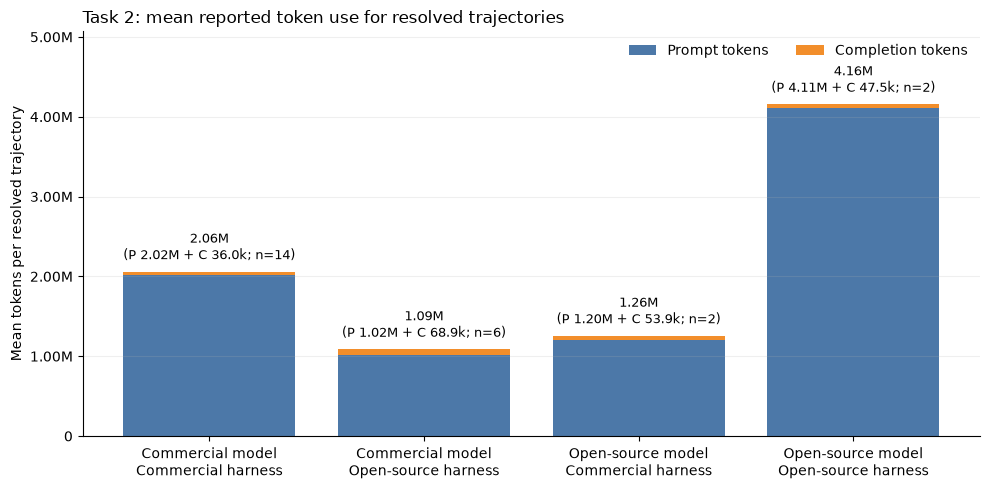

In [22]:
task_2_summary = resolved_summary(task_2_df)
display(task_2_summary)
plot_task_token_usage(
    task_2_df,
    "Task 2: mean reported token use for resolved trajectories",
)

## Task 2 resolved harness/model pairs

This makes the model/harness composition inside each quadrant visible.

In [23]:
task_2_pairs = pair_summary(task_2_df)
display(task_2_pairs)

,model_license,harness_license,harness,model,resolved_runs,median_steps,median_duration_min,median_total_tokens
4,commercial,commercial,codex,gpt-5.6-terra,4,25.5,4.8,"947,592.0"
1,commercial,commercial,claude-code,claude-opus-4-7,3,46.0,20.0,"2,047,193.0"
3,commercial,commercial,codex,gpt-5.6-luna,3,50.0,6.7,"4,653,871.0"
2,commercial,commercial,codex,gpt-5.5,2,57.5,7.8,"1,141,743.0"
5,commercial,commercial,cursor-cli,cursor/grok-4.5,1,26.0,3.2,"418,046.0"
6,commercial,commercial,gemini-cli,gemini-3.1-pro-preview,1,34.0,9.2,"917,115.0"
8,commercial,open-source,terminus-2,anthropic/claude-fable-5,3,25.0,19.3,"384,721.0"
9,commercial,open-source,terminus-2,anthropic/claude-opus-4-7,3,48.0,25.0,"1,682,868.0"
0,open-source,commercial,claude-code,glm-5.1,2,49.0,29.9,"1,256,175.0"
7,open-source,open-source,mini-swe-agent,openai/muse-spark-1.1,2,54.5,11.7,"4,155,665.0"


## Task 2 recorded tools

The hard task includes shell work, external data retrieval, planning, native web tools, file tools, and—in some Claude Code runs—delegated subagents.

In [24]:
task_2_tools = recorded_tool_summary(task_2_df)
display(task_2_tools)

,model_license,harness_license,recorded_action,count
20,commercial,commercial,exec,250
7,commercial,commercial,Bash,69
16,commercial,commercial,exec_command,68
9,commercial,commercial,no recorded action,61
12,commercial,commercial,WebFetch,27
31,commercial,commercial,run_shell_command,25
18,commercial,commercial,write_stdin,23
25,commercial,commercial,shellToolCall,15
11,commercial,commercial,TodoWrite,12
17,commercial,commercial,web_search_call,12


## Task 2 representative resolved runs

One median-step representative is selected for each of the four combinations.

In [25]:
task_2_representatives = select_representatives(task_2_df)
display(task_2_representatives[[
    "model_license", "harness_license", "harness", "model",
    "trajectory_id", "steps", "duration_min", "prompt_tokens",
    "completion_tokens", "total_tokens",
]])

,model_license,harness_license,harness,model,trajectory_id,steps,duration_min,prompt_tokens,completion_tokens,total_tokens
0,open-source,commercial,claude-code,glm-5.1,tbench21:079bf57d-3e27-5f51-8638-766741aac5b7,21,30.5,"260,735.0","38,423.0","299,158.0"
1,commercial,commercial,gemini-cli,gemini-3.1-pro-preview,tbench21:cb12d0b1-f9e1-55cb-a88e-58055235b75e,34,9.2,"895,906.0","21,209.0","917,115.0"
2,open-source,open-source,mini-swe-agent,openai/muse-spark-1.1,tbench21:184d8586-8692-51cc-a777-651f6e9c72dd,53,10.3,"3,148,598.0","42,490.0","3,191,088.0"
3,commercial,open-source,terminus-2,anthropic/claude-fable-5,tbench21:84065de3-f8ec-5cbe-b951-22ebe783cbc4,26,19.3,"305,115.0","57,841.0","362,956.0"


## Task 2 complete trajectories

Expand each row to inspect the complete resolved trajectory. Set `SHOW_ALL_TASK_2_RESOLVED = True` to display every resolved Task 2 run.

In [26]:
SHOW_ALL_TASK_2_RESOLVED = False

task_2_ids = (
    task_2_df["trajectory_id"].tolist()
    if SHOW_ALL_TASK_2_RESOLVED
    else task_2_representatives["trajectory_id"].tolist()
)
print(f"Displaying {len(task_2_ids)} complete Task 2 trajectories.")
for trajectory_id in task_2_ids:
    display_complete_trajectory(trajectory_by_id[trajectory_id])

Displaying 4 complete Task 2 trajectories.


## Interpretation notes

- Task 1 has a ceiling effect; its differences mainly describe harness overhead.
- Task 2 exposes research, component-selection, sequence-construction, and constraint-validation behavior.
- The four combinations are descriptive groups rather than causal estimates because they contain different model/harness pairs.
- Recorded step and tool representations are not fully equivalent across harness formats.